*  DSC630-T303 Predictive Analytics (2267-1)
*  4.2 Assignment: Clustering Algorithms
*  David Jorgensen

# 4.2 Assignment: Clustering Algorithms

In [1]:
# Import libraries for data handling, scaling, clustering, dimensionality
# reduction, evaluation, and plotting.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler   # standardize features
from sklearn.cluster import KMeans                  # K-means clustering
from sklearn.metrics import silhouette_score        # cluster quality metric
from sklearn.decomposition import PCA                # dimensionality reduction

# Make plots render inline and use a clean style.
%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")

## Step 1: Load the data and remove columns not relevant to the ALS condition

The dataset holds one row per patient with summary statistics (max / median /
min / range) of clinical measurements plus two identifier columns. `ID` and
`SubjectID` are record identifiers, not clinical measurements, so they carry no
information about a patient's ALS condition and are dropped before clustering.

In [2]:
# Load the ALS patient dataset.
df = pd.read_csv("data/als_data.csv")

# Inspect the raw shape and first rows to understand the structure.
print("Raw shape (rows, columns):", df.shape)
df.head()

Raw shape (rows, columns): (2223, 101)


,ID,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,...,Sodium_min,Sodium_range,SubjectID,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
0,1,65,57.0,40.5,38.0,0.066202,-0.965608,30,28.0,22,...,143.0,0.017422,533,8,7.0,7,0.002646,6.0,6.0,6.0
1,2,48,45.0,41.0,39.0,0.010453,-0.921717,37,33.0,21,...,136.0,0.010453,649,8,7.0,5,0.005386,7.0,5.0,5.0
2,3,38,50.0,47.0,45.0,0.008929,-0.914787,24,14.0,10,...,140.0,0.008929,1234,5,0.0,0,0.008929,6.0,5.0,5.0
3,4,63,47.0,44.0,41.0,0.012111,-0.598361,30,29.0,24,...,138.0,0.012469,2492,5,5.0,3,0.004988,7.0,6.0,5.0
4,5,63,47.0,45.5,42.0,0.008292,-0.444039,32,27.5,20,...,138.0,0.008292,2956,6,4.0,1,0.008489,6.0,5.0,5.0


In [3]:
# ID and SubjectID are only record identifiers -- they say nothing about the
# patient's ALS condition, so they are removed. Everything else is a clinical
# measurement relevant to ALS and is kept.
id_cols = ["ID", "SubjectID"]
als = df.drop(columns=id_cols)

# Confirm the identifiers are gone and check for missing values.
print("Shape after dropping identifiers:", als.shape)
print("Total missing values:", als.isna().sum().sum())
als.head()

Shape after dropping identifiers: (2223, 99)
Total missing values: 0


,Age_mean,Albumin_max,Albumin_median,Albumin_min,Albumin_range,ALSFRS_slope,ALSFRS_Total_max,ALSFRS_Total_median,ALSFRS_Total_min,ALSFRS_Total_range,...,Sodium_median,Sodium_min,Sodium_range,trunk_max,trunk_median,trunk_min,trunk_range,Urine.Ph_max,Urine.Ph_median,Urine.Ph_min
0,65,57.0,40.5,38.0,0.066202,-0.965608,30,28.0,22,0.021164,...,145.5,143.0,0.017422,8,7.0,7,0.002646,6.0,6.0,6.0
1,48,45.0,41.0,39.0,0.010453,-0.921717,37,33.0,21,0.028725,...,138.0,136.0,0.010453,8,7.0,5,0.005386,7.0,5.0,5.0
2,38,50.0,47.0,45.0,0.008929,-0.914787,24,14.0,10,0.025000,...,143.0,140.0,0.008929,5,0.0,0,0.008929,6.0,5.0,5.0
3,63,47.0,44.0,41.0,0.012111,-0.598361,30,29.0,24,0.014963,...,139.0,138.0,0.012469,5,5.0,3,0.004988,7.0,6.0,5.0
4,63,47.0,45.5,42.0,0.008292,-0.444039,32,27.5,20,0.020374,...,140.0,138.0,0.008292,6,4.0,1,0.008489,6.0,5.0,5.0


## Step 2: Apply a standard scaler to the data

K-means uses Euclidean distance, so features on large numeric scales (e.g.
Platelets in the hundreds) would dominate features on small scales (e.g. range
ratios near zero). `StandardScaler` rescales every feature to mean 0 and
standard deviation 1 so each contributes equally to the distance.

In [4]:
# Standardize all clinical features to mean 0 / std 1.
scaler = StandardScaler()
als_scaled = scaler.fit_transform(als)

# Quick check: scaled means ~0 and stds ~1 across features.
print("Scaled data shape:", als_scaled.shape)
print("Mean of first 5 features:", np.round(als_scaled.mean(axis=0)[:5], 4))
print("Std  of first 5 features:", np.round(als_scaled.std(axis=0)[:5], 4))

Scaled data shape: (2223, 99)
Mean of first 5 features: [-0. -0. -0. -0.  0.]
Std  of first 5 features: [1. 1. 1. 1. 1.]


## Step 3: Plot silhouette score versus the number of K-means clusters

The silhouette score measures how well each point sits inside its own cluster
versus the nearest other cluster (range -1 to 1; higher is better). Fit K-means
for a range of `k` values and record the silhouette score for each.

In [5]:
# Try cluster counts from 2 through 10 (silhouette needs at least 2 clusters).
k_values = range(2, 11)
sil_scores = []

for k in k_values:
    # Fit K-means for this k. random_state fixes results; n_init=10 runs several
    # centroid seeds and keeps the best.
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(als_scaled)
    # Average silhouette score over all points for this clustering.
    score = silhouette_score(als_scaled, labels)
    sil_scores.append(score)
    print(f"k = {k:2d}  ->  silhouette score = {score:.4f}")

k =  2  ->  silhouette score = 0.0787
k =  3  ->  silhouette score = 0.0682


k =  4  ->  silhouette score = 0.0708


k =  5  ->  silhouette score = 0.0564
k =  6  ->  silhouette score = 0.0708


k =  7  ->  silhouette score = 0.0476


k =  8  ->  silhouette score = 0.0492
k =  9  ->  silhouette score = 0.0486


k = 10  ->  silhouette score = 0.0383


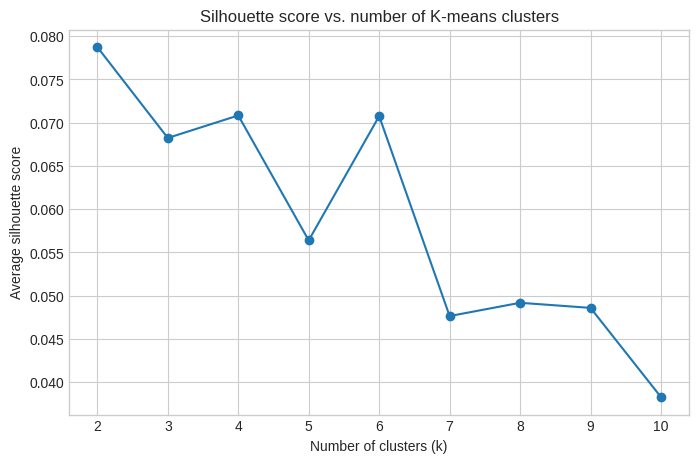

In [6]:
# Plot silhouette score against number of clusters.
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), sil_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("Silhouette score vs. number of K-means clusters")
plt.xticks(list(k_values))
plt.show()

## Step 4: Choose an optimal number of clusters

The silhouette score is highest at **k = 2** (~0.079) and falls off as more
clusters are added. A higher silhouette means tighter, better-separated
clusters, so **k = 2** is the optimal choice: it gives the cleanest split of
the patients that the data supports. (The scores are low overall, which tells
us the patients do not form strongly separated groups -- discussed in the
conclusion -- but k = 2 is still the best-supported option.)

## Step 5: Fit a K-means model with the optimal number of clusters

In [7]:
# Fit the final K-means model with k = 2 (chosen in Step 4).
optimal_k = 2
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(als_scaled)

# Report how many patients landed in each cluster.
print("Optimal k:", optimal_k)
print("Final silhouette score:", round(silhouette_score(als_scaled, clusters), 4))
print("Cluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

Optimal k: 2
Final silhouette score: 0.0787
Cluster sizes:
0    1111
1    1112
Name: count, dtype: int64


## Step 6: Fit a PCA transformation with two features

The scaled data has 99 dimensions, which cannot be plotted directly. PCA
compresses it into two components that capture the most variance, letting us
visualize the clusters in 2-D.

In [8]:
# Reduce the scaled features to 2 principal components.
pca = PCA(n_components=2, random_state=42)
als_pca = pca.fit_transform(als_scaled)

# Report how much variance each component explains.
evr = pca.explained_variance_ratio_
print("Explained variance ratio:", np.round(evr, 4))
print("Total variance captured by 2 components:", round(evr.sum(), 4))

Explained variance ratio: [0.1133 0.0645]
Total variance captured by 2 components: 0.1778


## Step 7: Scatterplot of the PCA-transformed data colored by cluster

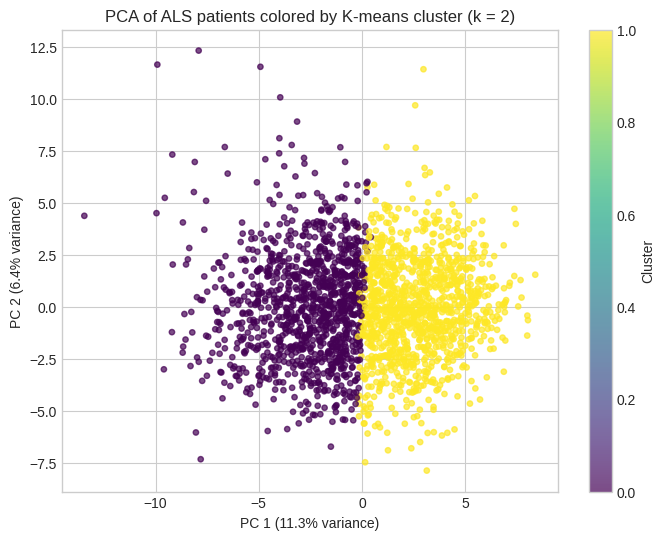

In [9]:
# Plot the two PCA components, coloring each patient by its K-means cluster.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(als_pca[:, 0], als_pca[:, 1],
                      c=clusters, cmap="viridis", s=15, alpha=0.7)
plt.xlabel(f"PC 1 ({evr[0]*100:.1f}% variance)")
plt.ylabel(f"PC 2 ({evr[1]*100:.1f}% variance)")
plt.title("PCA of ALS patients colored by K-means cluster (k = 2)")
plt.colorbar(scatter, label="Cluster")
plt.show()

## Step 8: Summary and conclusion

**Process.** I loaded the ALS dataset (2,223 patients), removed the two
identifier columns (`ID`, `SubjectID`) that carry no clinical meaning, and
standardized the remaining 99 clinical features so each contributes equally to
K-means' distance calculation. Sweeping `k` from 2 to 10 and scoring each with
the silhouette metric showed the score peaking at **k = 2** and declining
afterward, so I fit the final K-means model with two clusters. PCA reduced the
99 features to two components for visualization.

**Results.** The two clusters split the patients into two groups (sizes printed
in Step 5). In the PCA scatterplot the clusters separate mainly along the first
principal component, but the two PCA components together explain only a small
share of the total variance, and the peak silhouette score (~0.079) is low.

**Conclusion.** K-means with k = 2 is the best-supported clustering, but the low
silhouette scores across every k and the modest PCA separation indicate the ALS
patients do not form naturally distinct, well-separated groups. The clustering
divides patients along the dominant axis of variation (roughly, overall
disease-severity / measurement level), yet the boundary between groups is soft
rather than sharp. Practically, this data behaves more like a continuum of
patient states than a set of crisp clusters, so any grouping should be treated
as a coarse summary rather than firm patient subtypes. Additional feature
engineering or a density-based / soft-clustering method might reveal more
structure.